# Samuel — Regression Round 2

KASDAD TP2 · Feature attribution, training history sensitivity & temporal generalization

## Motivation & hypotheses

Round 1: expanded structured HGB improves primary MAE but harms early H12. We ask which feature groups contribute, whether more recent observations matter at matched sample size, and which residual segments remain difficult. Conditional-median reasoning from REG-Lite B remains relevant to MAE; its TP1 multiclass recipe is not copied.

## Context & Methods

Same six 4-cycle primary windows and two H12 views, 38,588 records per family. H12 overlaps primary. The whole Train has already been explored; this is adaptive development evidence, not an untouched test. Fixed absolute-error HGB, 200 iterations, 15 leaves, learning rate .05, minimum leaf 30, L2 1, seed 42, no early stopping, two threads. Five controlled group removals; recent 8/12 histories; exact-size random past samples with two fixed seeds. Up to four adaptive interactions were separately frozen before their fits.

### Key assumptions

Cycle order represents earlier/later observations, not a verified calendar. Additional structured features retain supplied-schema eligibility and provisional operational timing. Matched row counts do not remove composition or temporal confounding. Official Test features are descriptive only; the research pipeline never predicts Test. The separate initial-submission track uses older frozen recipes and does not select these experiments.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
while not (ROOT/'src/utils/paths.py').is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT/'src/utils/paths.py').is_file():
    raise FileNotFoundError('Open this notebook inside the TP2 repository.')
sys.path.insert(0, str(ROOT))
from src.models.regression_round2_evaluation import verify_freeze, load_protocol, run_round2
from src.models.regression_round2_reporting import load_results, comparison_frame, build_report
freeze = verify_freeze()
protocol = load_protocol()
# Reconstruct only the already-selected frozen recipes if ignored local vectors are missing.
result_path = ROOT/'reports/regression_round2/results.json'
old = json.loads(result_path.read_text(encoding='utf-8')) if result_path.exists() else None
needed = [ROOT/'experiments/runs/regression_round2_v1'/f"fit{end}__{r['id']}.npz"
          for end in [55,59,63,67,71,75] for r in (old['recipes'] if old else protocol['recipes'])]
if not old or not all(p.exists() for p in needed):
    import contextlib, io
    with contextlib.redirect_stdout(io.StringIO()):
        run_round2(stage='all')
results = load_results()
summary = comparison_frame(results)
print('Freeze:', freeze['signature'])
print(len(results['recipes']), 'recipes;', len(results['jobs']), 'window evaluations')
print('Protected checkpoint files:', len(freeze['protected_checkpoint_files']))

Freeze: a94ae9ae44b1dfe9b48a632806df4ed61ff1278d876f1dea2aa0c6e24188f3c3
19 recipes; 152 window evaluations
Protected checkpoint files: 196


## tl;dr

The table below identifies the lowest observed primary and H12 MAE separately. These are review candidates, not final model decisions. **Full expanded recent-8 leads primary; expanding without category codes leads H12.** Category removal helps early H12 but harms late H12 and the high target tail. Recent history does not improve long-horizon results consistently. Removing cycle becomes less costly with recent history, while still trailing the full recent model. Read these counterexamples before interpreting pooled gains.

In [2]:
for metric in ['Primary MAE', 'H12 MAE']:
    best = summary.loc[summary[metric].idxmin()]
    print(f"Lowest observed {metric}: {best['Recipe']} = {best[metric]:.6f}")
display(summary[['Recipe','Primary MAE','Equal-cycle MAE','H12 MAE','H12_E','H12_L']].round(5))

Lowest observed Primary MAE: B_D_RECENT8 = 13.217154
Lowest observed H12 MAE: A_NO_CODES = 15.053467


,Recipe,Primary MAE,Equal-cycle MAE,H12 MAE,H12_E,H12_L
0,R1_C,15.14899,15.25409,15.47789,16.43213,14.67056
1,R1_D,13.34984,13.58966,15.57724,17.79560,13.70039
2,A_NO_CYCLE,14.21410,14.36693,15.58209,17.49557,13.96319
3,A_NO_CODES,14.07860,14.19002,15.05347,16.13209,14.14090
4,A_NO_SCOPE_SPREAD,13.39140,13.63418,15.61612,17.91902,13.66775
5,A_NO_TELEMETRY,13.45204,13.68174,15.68819,17.82515,13.88021
6,A_NO_TEXT_LOAD,13.42015,13.67179,15.58673,17.86520,13.65903
7,B_C_RECENT8,15.09719,15.22887,15.62919,16.43528,14.94719
8,B_C_RECENT12,15.13622,15.24960,15.56255,16.43213,14.82685
9,B_C_MATCHED8_S42,15.16931,15.27606,15.53250,16.43626,14.76788


## Experimental design

The two exact controls delegate to Round 1. Feature removals drop all derived columns associated with a raw feature. Encoders/imputers are fitted solely on selected past rows. Recent histories preserve complete cycles; matched samples are target-blind individual-row samples from expanding history, with exactly the recent-8 count. Their two seeds measure limited sample sensitivity.

Feature/history interactions are explicitly adaptive. Their numerical selection rationale and immutable signature are shown below; no test features or Kaggle scores are used for that choice.

In [3]:
display(pd.DataFrame([{'family':f, **w} for f,k in [('primary','primary_windows'),('H12','secondary_windows')] for w in protocol[k]]))
selection = json.loads((ROOT/'experiments/regression_round2/interaction_selection.json').read_text(encoding='utf-8'))
print('Interaction selection:', selection['signature'])
print(selection['payload']['rationale'])
display(pd.DataFrame(results['recipes']))

,family,id,fit,validation
0,primary,W1,"[47, 55]","[56, 59]"
1,primary,W2,"[47, 59]","[60, 63]"
2,primary,W3,"[47, 63]","[64, 67]"
3,primary,W4,"[47, 67]","[68, 71]"
4,primary,W5,"[47, 71]","[72, 75]"
5,primary,W6,"[47, 75]","[76, 79]"
6,H12,H12_E,"[47, 55]","[56, 67]"
7,H12,H12_L,"[47, 67]","[68, 79]"


Interaction selection: 16f4f61ea8ff3be38c3b1ff0525742b4f6d66772e33fb43947cc2a9299715873
Selected exactly two removals and four history interactions from the predeclared budget. Base expanding R1-D primary/H12 MAE 13.349836/15.577241. Removing codes gives primary 14.078598 but H12 15.053470: early H12 improves 17.795600 to16.132086 while late H12 worsens13.700392 to14.140896 and high-tail errors worsen. This is a substantive feature/history trade-off, not universal robustness. Removing cycle produces the largest primary removal cost (+0.864267) but nearly neutral pooled H12 (+0.004850), with early improvement and late loss, making it the second informative contrast. Full D recent8 primary13.217154 beats expanding13.349836 and matched8 samples13.501782/13.528531 at equal recent8 row count, but H12 worsens to15.794559; recent12 also fails to improve either H12. Interactions test whether category/cycle removal changes that recency-versus-count contrast. No scope/spread, telemetry or text-l

,id,features,history,control,stage
0,R1_C,two,expanding,R1_C,base
1,R1_D,full,expanding,R1_D,base
2,A_NO_CYCLE,no_cycle,expanding,None,base
3,A_NO_CODES,no_codes,expanding,None,base
4,A_NO_SCOPE_SPREAD,no_scope_spread,expanding,None,base
5,A_NO_TELEMETRY,no_telemetry,expanding,None,base
6,A_NO_TEXT_LOAD,no_text_load,expanding,None,base
7,B_C_RECENT8,two,recent8,R1_C,base
8,B_C_RECENT12,two,recent12,R1_C,base
9,B_C_MATCHED8_S42,two,matched8_s42,R1_C,base


## Results — feature contribution

Negative removal-minus-full MAE means that removing the group helped this fitted model. A zero or positive result does not establish universal feature usefulness. R1-D's W1/H12 early counterexample is retained.

The reusable plotting code lives in `src/models/regression_round2_reporting.py`; each figure is regenerated from saved metrics and verified vectors, then embedded for portable viewing.

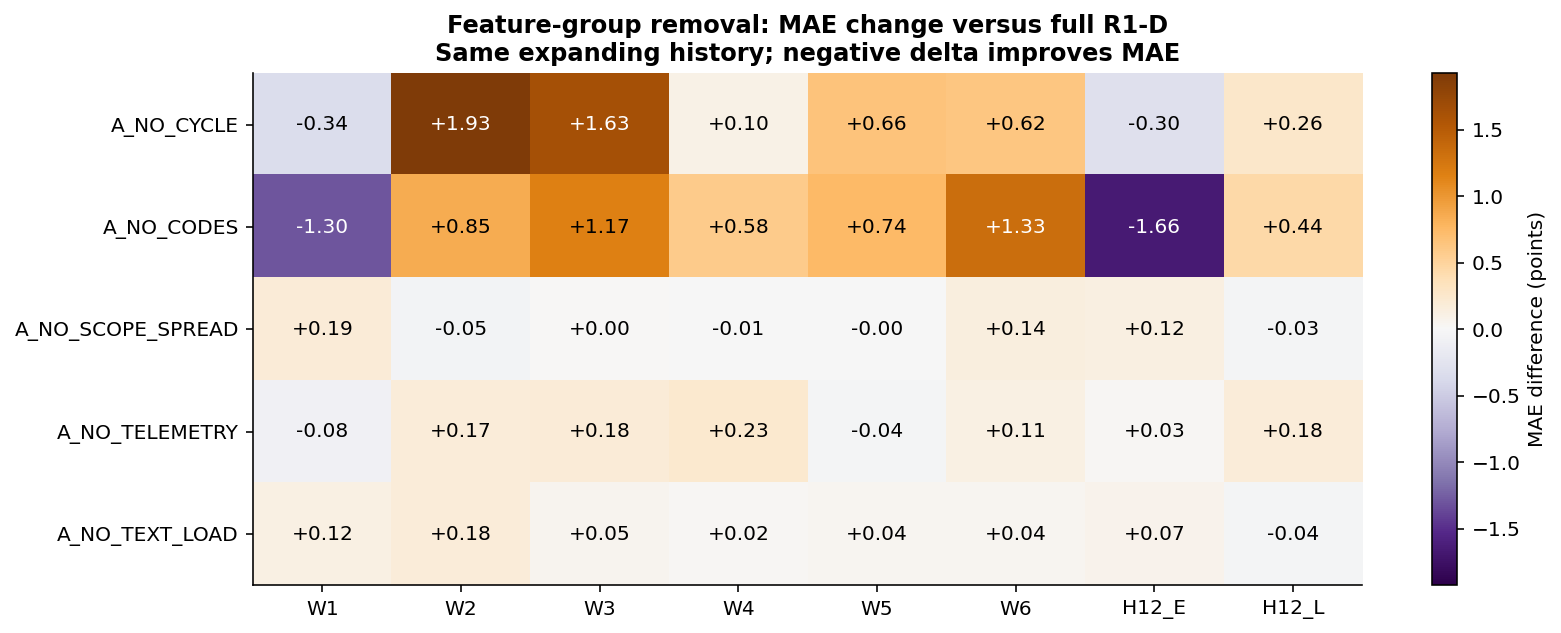

In [4]:
figure_paths = build_report()
diagnostics = json.loads((ROOT/'reports/regression_round2/behavior_diagnostics.json').read_text(encoding='utf-8'))
display(Image(filename=str(ROOT/'reports/regression_round2/figures/regression_round2_ablation_window_deltas.png')))

## Results — history and feature × history

Equal sample count partially separates data volume from period selection. Training composition, category novelty and dependence still vary. Interactions compare a removal against the full model under the same history, then against the corresponding expanding-history contrast; they are predictive refit contrasts.

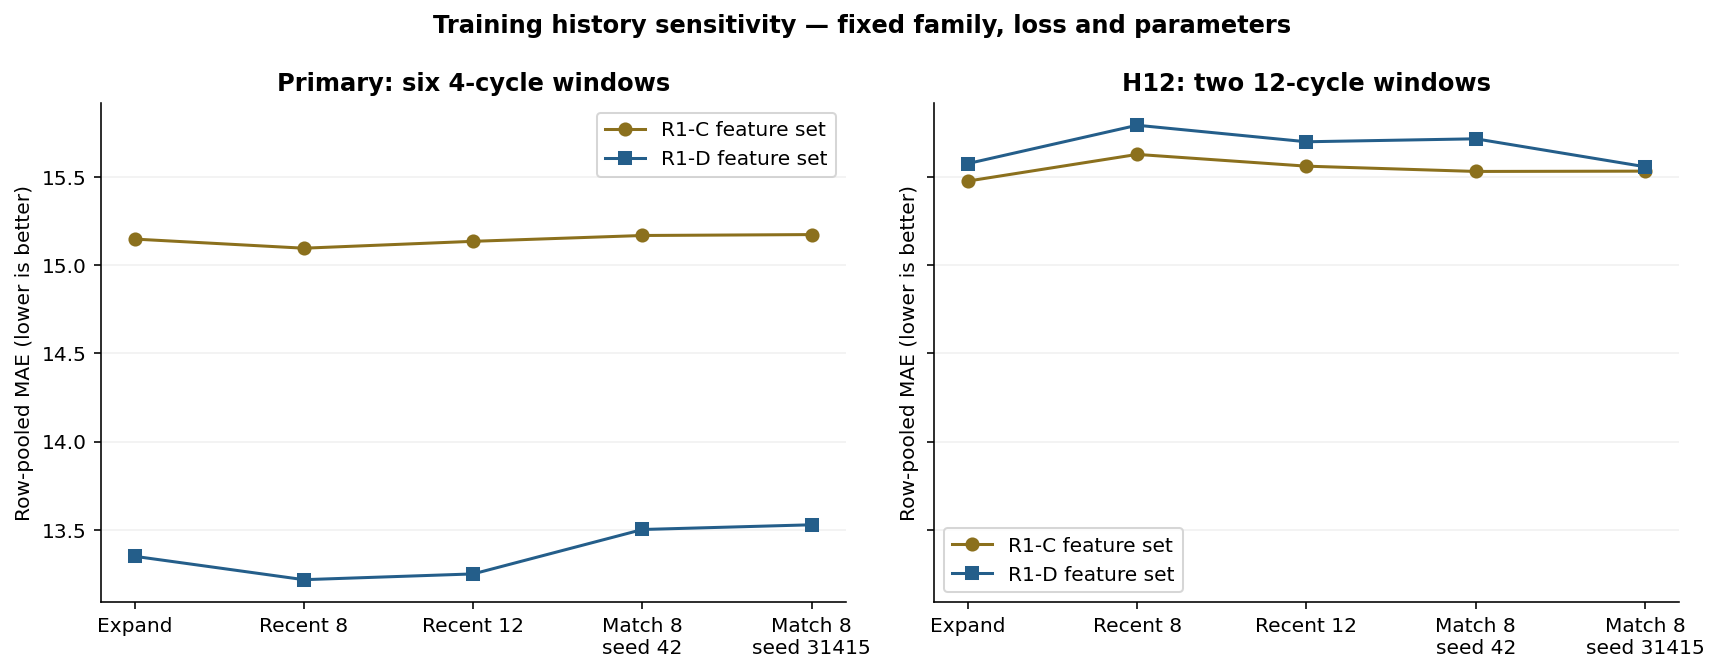

,recipe,family,ablation_delta_same_history,ablation_delta_expanding,difference_in_differences
0,C_NO_CODES_RECENT8,primary,0.80596,0.72876,0.07720
1,C_NO_CODES_RECENT8,secondary,-0.51857,-0.52377,0.00520
2,C_NO_CODES_MATCHED8_S42,primary,0.71576,0.72876,-0.01301
3,C_NO_CODES_MATCHED8_S42,secondary,-0.55359,-0.52377,-0.02982
4,C_NO_CYCLE_RECENT8,primary,0.26597,0.86427,-0.59829
5,C_NO_CYCLE_RECENT8,secondary,-0.21503,0.00485,-0.21988
6,C_NO_CYCLE_MATCHED8_S42,primary,0.78412,0.86427,-0.08015
7,C_NO_CYCLE_MATCHED8_S42,secondary,-0.01668,0.00485,-0.02153


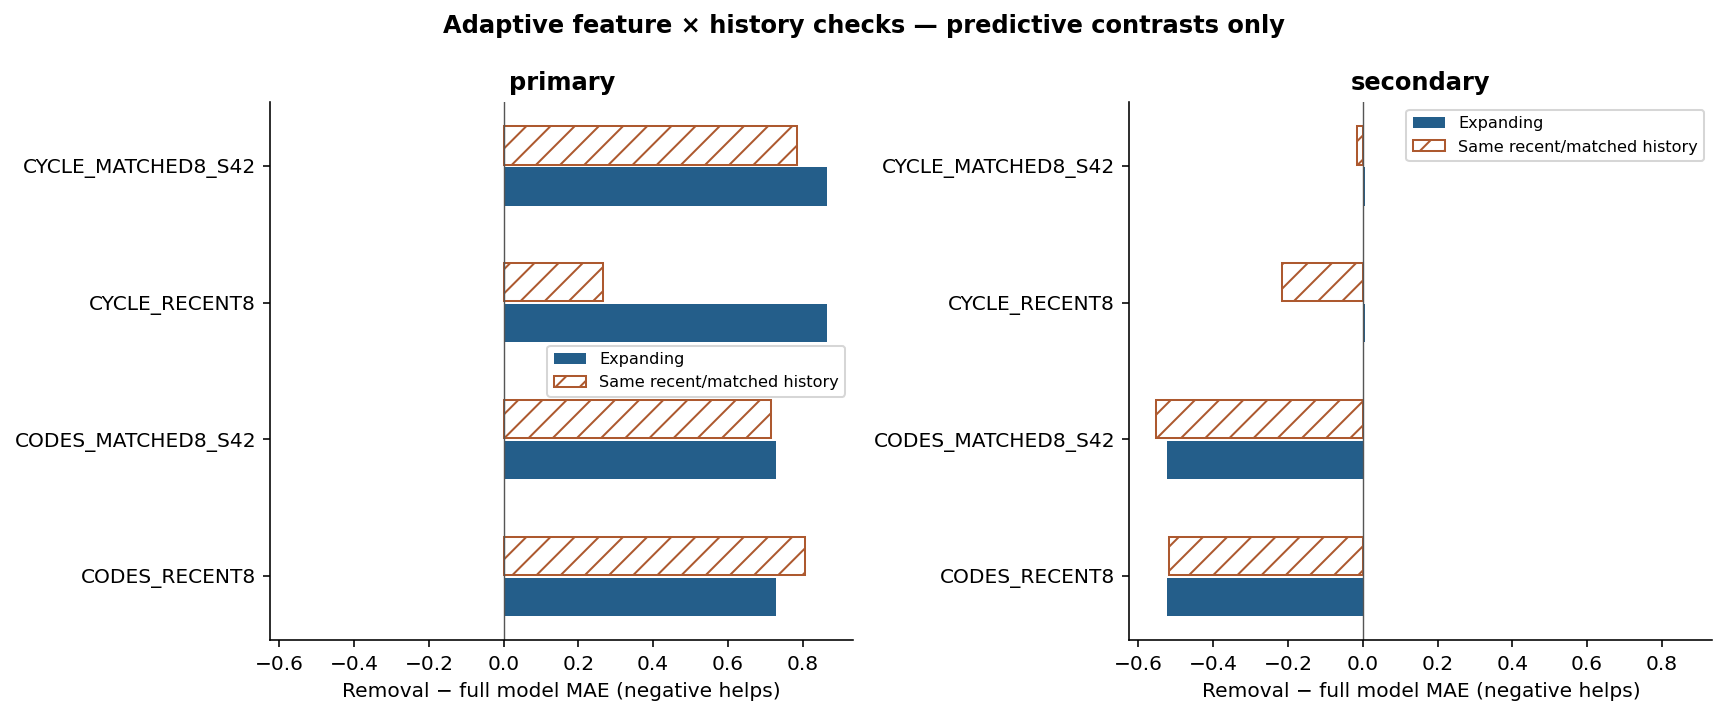

In [5]:
display(Image(filename=str(ROOT/'reports/regression_round2/figures/regression_round2_history_comparison.png')))
display(pd.DataFrame(diagnostics['interactions']).drop(columns=['interpretation']).round(5))
if diagnostics['interactions']:
    display(Image(filename=str(ROOT/'reports/regression_round2/figures/regression_round2_feature_history_interactions.png')))

## Results — residuals, tails and horizon

Signed error is prediction minus actual. Actual target bins are evaluation-only and never used as an inference gate. Small pooled bias can conceal overprediction at low targets and underprediction at high targets. H12 lead profiles change era and horizon together.

,Recipe,RMSE,Signed error,EF0,EF1,Low tail,High tail
0,R1_C,19.05746,-0.28572,16.81747,11.68322,20.79203,16.72404
1,R1_D,17.35763,-0.03715,14.57347,10.80812,18.22137,11.51482
2,A_NO_CYCLE,18.40214,0.34208,15.60358,11.32789,19.31742,11.88244
3,A_NO_CODES,18.10640,0.16432,15.49678,11.13278,18.18869,13.19468
4,A_NO_SCOPE_SPREAD,17.39528,0.04538,14.61066,10.85875,18.33720,11.61101
5,A_NO_TELEMETRY,17.45358,-0.42912,14.68748,10.88578,17.27304,11.93093
6,A_NO_TEXT_LOAD,17.38924,0.01963,14.66084,10.84300,18.51116,11.63927
7,B_C_RECENT8,19.24949,-0.19852,16.79139,11.57803,18.54622,15.43991
8,B_C_RECENT12,19.19235,-0.35697,16.82389,11.63060,19.03190,16.00995
9,B_C_MATCHED8_S42,19.06543,-0.24210,16.84799,11.68236,20.81198,16.80584


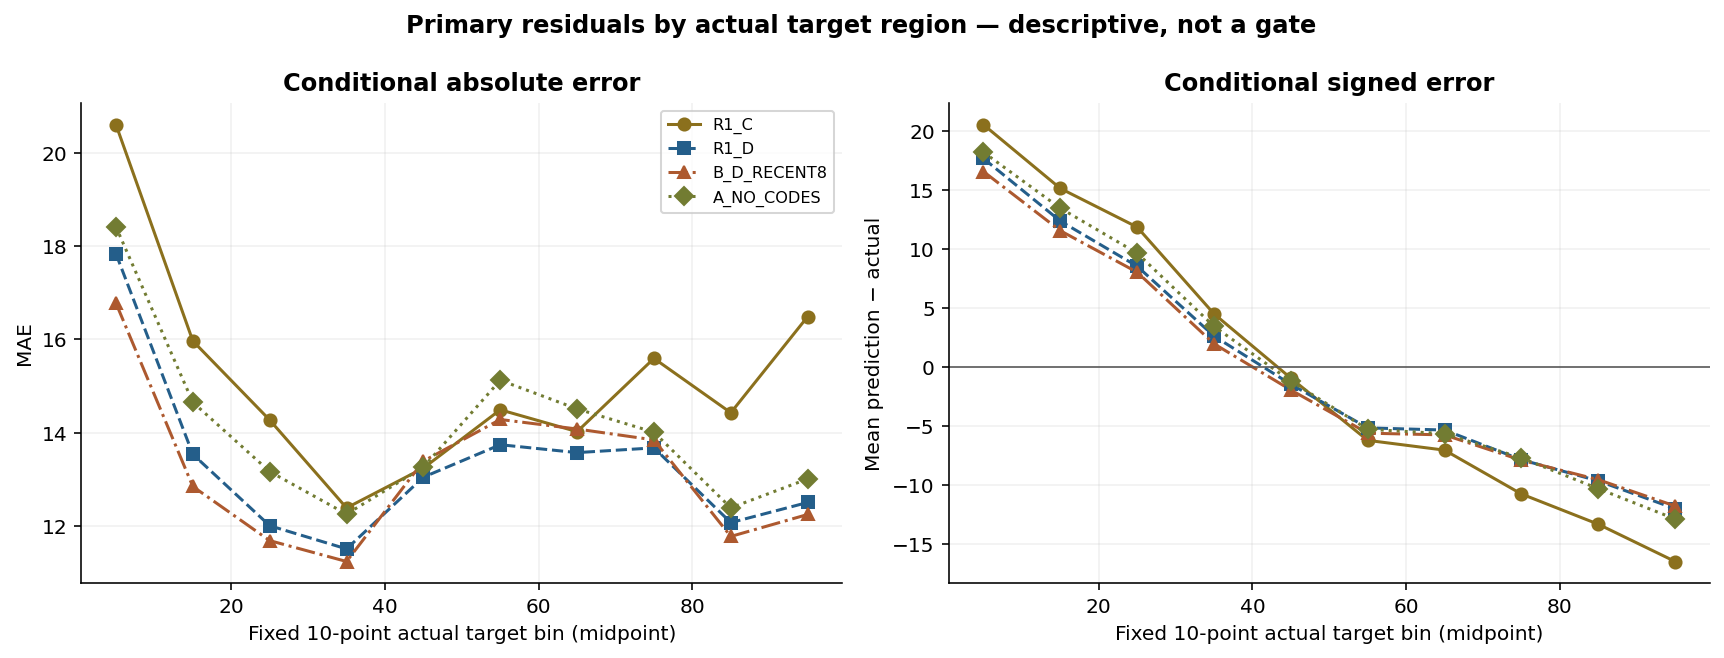

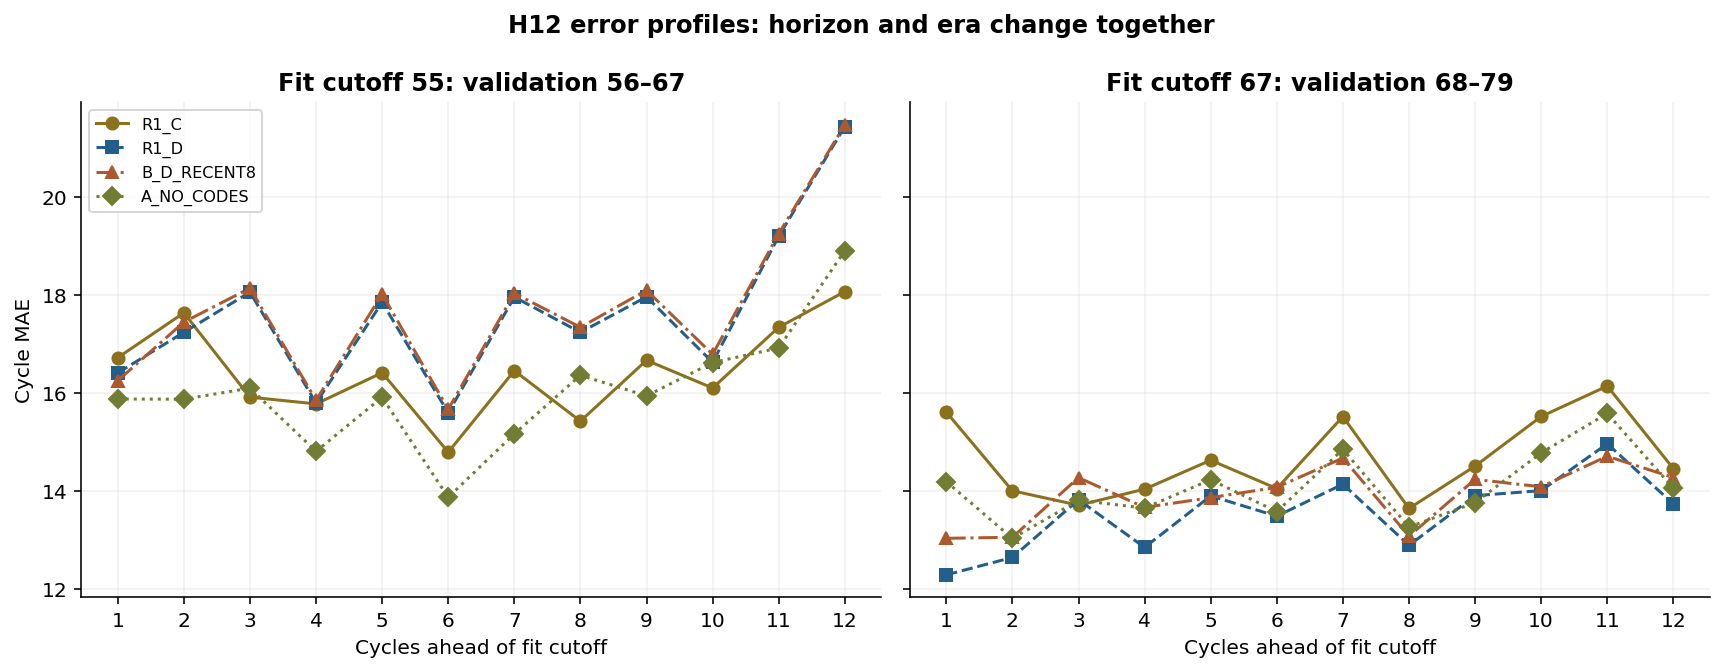

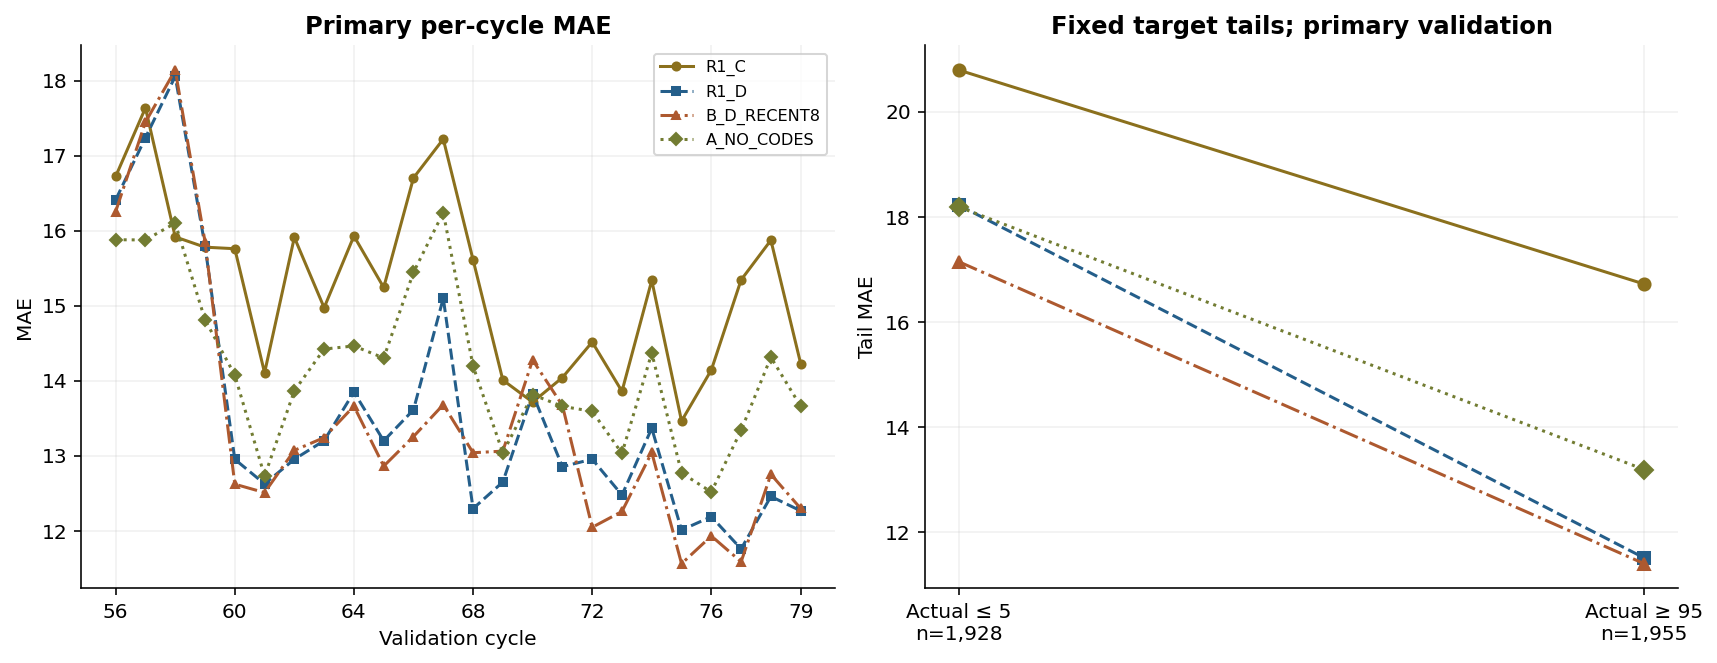

In [6]:
display(summary[['Recipe','RMSE','Signed error','EF0','EF1','Low tail','High tail']].round(5))
display(Image(filename=str(ROOT/'reports/regression_round2/figures/regression_round2_target_region_residuals.png')))
display(Image(filename=str(ROOT/'reports/regression_round2/figures/regression_round2_horizon_profiles.png')))
display(Image(filename=str(ROOT/'reports/regression_round2/figures/regression_round2_cycle_and_tail_errors.png')))

## Results — descriptive generalization risk

These checks use official Test predictors after experiment selection. They do not reveal Test labels or establish actual future MAE. Unknown category handling prevents a preprocessing failure; it does not guarantee that unknown categories are predictable. Numeric cycle trees partition observed support and do not extrapolate a learned time slope.

In [7]:
risk = diagnostics['official_test_feature_risk']
print('Cycle gap:', risk['cycle_gap'])
display(pd.DataFrame([{'feature':name,'train missing rate':v['train_missing_rate'],'test missing rate':v['test_missing_rate'],
                      'test unknown n':v.get('test_unknown_n'),'KS distance':v.get('descriptive_ks_distance')}
                     for name,v in risk['features'].items()]).round(5))

Cycle gap: {'train_min': 47.0, 'train_max': 79.0, 'test_min': 80.0, 'test_max': 91.0, 'test_outside_train_range_n': 29421, 'test_outside_train_range_rate': 1.0}


,feature,train missing rate,test missing rate,test unknown n,KS distance
0,impact_load,0.00000,0.00000,NaN,0.09434
1,entry_friction,0.00000,0.00000,NaN,0.06134
2,cycle_code,0.00000,0.00000,NaN,NaN
3,scope_pressure,0.00000,0.00000,NaN,0.21376
4,text_load,0.00000,0.00000,NaN,0.15511
5,scope_trace,0.08362,0.08273,NaN,0.21384
6,org_spread,0.08611,0.08389,NaN,0.21300
7,module_spread,0.08218,0.08501,NaN,0.21367
8,telemetry_flag,0.11269,0.11115,NaN,NaN
9,org_code,0.05307,0.23269,4732.0,NaN


## Interpretation, limitations & next steps

Read [FINDINGS.md](../../reports/regression_round2/FINDINGS.md) for the evidence-led interpretation, counterexamples and Round 3 recommendations, and [COMPARISON_TABLES.md](../../reports/regression_round2/COMPARISON_TABLES.md) for every candidate/window/cycle and subgroup. The complete exact-impact tables and conditional IQR diagnostics remain in JSON to keep this notebook short.

Absolute-error fitting targets conditional medians. Tail shrinkage alone is not a reason to apply percentile calibration: ranking quality, conditional spread and MAE trade-offs still need a separate preregistered study. Feature ablation is conditional predictive evidence, and matched-size sampling is not a causal estimate of recency. No automatic model zoo, target transform, text experiment or Round 3 follows this milestone.

## Checks

Independent verification reconciles saved vectors, original control equality, fit-only preprocessing and temporal ordering. The receipt below records what was actually checked; representative repeat evidence is claimed only when present and identity-bound.

In [8]:
receipt = json.loads((ROOT/'reports/regression_round2/verification.json').read_text(encoding='utf-8'))
assert receipt['status'] == 'PASS'
assert receipt['freeze_signature'] == freeze['signature']
import hashlib
assert receipt['results_sha256'] == hashlib.sha256(result_path.read_bytes()).hexdigest()
display(pd.Series({k:v for k,v in receipt.items() if not isinstance(v,(dict,list))}))
print('Representative repeat:', receipt['repeat_verification'])
print('No official-test predictions, classification refits or Kaggle selection occur in this notebook.')

status                                                                         PASS
freeze_signature                  a94ae9ae44b1dfe9b48a632806df4ed61ff1278d876f1d...
round1_freeze_signature           7a6bfcb7900fa86f2df7e4ade61e9aac3ec617275a556f...
results_path                      C:\Users\Sam\OneDrive\Documents\KASDAD\TP 2\re...
results_sha256                    75e7d54ed58f414a271409481a59337fd030bb391e6d65...
vector_manifest_sha256            95b4e0c04aeb88eb31411ab4601856ace922895e79a431...
fit_audit_manifest_sha256         160437ca6570bd2d6807b4b099c09e3604030b1c7fa7d8...
model_fit_cache_checks                                                          114
job_metric_checks                                                               152
aggregate_checks                                                                 38
paired_comparison_checks                                                         76
exact_round1_control_checks                                                 

Representative repeat: {'status': 'PASS', 'checks': 38, 'freeze_signature': 'a94ae9ae44b1dfe9b48a632806df4ed61ff1278d876f1dea2aa0c6e24188f3c3', 'report_path': 'C:\\Users\\Sam\\AppData\\Local\\Temp\\tp2-regression-round2-repeat\\results.json', 'report_sha256': '144ba056ab48e0b088579214986d65fa4b62da4cdbea48a90330c846bd46f39b', 'vector_manifest_sha256': 'a5b3d895c1b680d7a2a23a15189cf3402f9f33c9b07076d687472bad1b00c6a1', 'fit_audit_manifest_sha256': '957f252822e35024a81c79a6741b8fc69457fbdd180dd0584797ab6d4ecc19e4'}
No official-test predictions, classification refits or Kaggle selection occur in this notebook.
